# CREST-GV quickstart

CREST-GV tests whether a set of trait-associated genetic variants is enriched in the
open chromatin of each cell type in a chromatin accessibility collection, relative to
a trait-agnostic background (1000 Genomes Project variants).

This notebook walks through the library API end to end against the small example
dataset bundled with the package (`../example_files/`) — three synthetic cell types, so
it runs in a few seconds and needs no external data. The same calls work against the
full reference atlas; see the final section for that.


In [1]:
from crestgv import crestgv, COLLECTION_NAME_DICT

print("Reference collections available in the atlas:")
for key, on_disk_name in COLLECTION_NAME_DICT.items():
    print(f"  {key:25s} -> {on_disk_name}")


Reference collections available in the atlas:
  cad                       -> CAD
  calderon                  -> calderon
  catlas_fetal              -> catlas_fetal
  catlas_adult              -> catlas_adult
  erythoid_d7_d10_d13_d17   -> Days7_10_13_17
  greenleaf_brain           -> greenleaf_brain
  h1_hescs                  -> H1_hESCs
  immune_cell               -> immune_cell
  ludwig2019                -> ludwig2019
  mpal                      -> MPAL
  super_pbmc                -> super_PBMC


## 1. The genetic variant file

The only mandatory input is a tab-separated file with **no header row** and exactly
three columns: variant ID, chromosome (`chr#`), 1-based position.


In [2]:
with open("../example_files/genetic.tsv") as f:
    for line in f:
        print(line.rstrip())


rs60692108	chr10	801748
rs74876360	chr10	823912
chr10-840700-A-C	chr10	840700


## 2. Running against an in-house collection

An in-house collection is a folder with `bigwigs/<cell_type>.bw`,
`peaks/<cell_type>_L-tron.bed` (or any 3-column BED of peak calls), and a
`<collection>_info.csv`. See [`../example_files/in-house-data`](../../example_files/in-house-data)
for the exact layout.


In [3]:
cgv = crestgv(
    genetic="../example_files/genetic.tsv",
    output="../example_output",
    min_number_genetics=1,  # the bundled example file is tiny; real runs use the default (500)
    in_house_collection_path="../example_files/in-house-data",
)
results = cgv.calculate_enrichment_score()
results


Loading 1000genome snps...
Checking and cleaning genetic file...
Processed genetic file. Retained 3 rows.
Total number of used variants in CREST-GV: 3
Calculating (1) total number of snps from 1000genomes within peaks ...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00,  8.34it/s]


Intersecting genetic variants with peak regions ...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 199.60it/s]

Calculating statistics ...
Processing genetics finished.


,n_snps,p_succes,GWAS_init,pmf,sf,check_np,check_n(1-p),p_hat,SE,Z,pdf,Z_norm,pdf_cgv_norm,CREST-GV,CREST-GV_pval,CREST-GV_norm,CREST-GV_pval_norm
cell_type_1,NaN,0.000006,0,0.999982,1.000000,0.000018,2.999982,0.000000,0.001426,-0.004279,0.501707,-0.577348,0.718148,-0.004279,0.501707,-0.577348,0.718148
cell_type_2,NaN,0.000008,0,0.999977,1.000000,0.000023,2.999977,0.000000,0.001595,-0.004784,0.501908,-0.577352,0.718149,-0.004784,0.501908,-0.577352,0.718149
cell_type_3,NaN,0.000006,1,0.000017,0.000017,0.000017,2.999983,0.333333,0.001356,245.871405,0.000000,1.154701,0.124107,245.871405,0.000000,1.154701,0.124107


Key columns:

- **`CREST-GV`** / **`CREST-GV_pval`** — the raw enrichment Z-score and its P-value,
  calibrated against the genome-wide background. Comparable across cell types *within*
  this collection, but not across collections of different size/composition.
- **`CREST-GV_norm`** / **`CREST-GV_pval_norm`** — the same Z-score standardised
  within this collection (subtract the mean, divide by the standard deviation across
  all of this collection's cell types). This is the statistic used throughout the
  CREST-GV paper, since it's what makes cell types from different collections
  comparable on a common scale.

A results file is also written to disk:


In [4]:
import pandas as pd

reloaded = pd.read_csv("../example_output/in-house-data_statistics_CREST-GV.csv", sep="\t", index_col=0)
reloaded


,n_snps,p_succes,GWAS_init,pmf,sf,check_np,check_n(1-p),p_hat,SE,Z,pdf,Z_norm,pdf_cgv_norm,CREST-GV,CREST-GV_pval,CREST-GV_norm,CREST-GV_pval_norm
cell_type_1,NaN,0.000006,0,0.999982,1.000000,0.000018,2.999982,0.000000,0.001426,-0.004279,0.501707,-0.577348,0.718148,-0.004279,0.501707,-0.577348,0.718148
cell_type_2,NaN,0.000008,0,0.999977,1.000000,0.000023,2.999977,0.000000,0.001595,-0.004784,0.501908,-0.577352,0.718149,-0.004784,0.501908,-0.577352,0.718149
cell_type_3,NaN,0.000006,1,0.000017,0.000017,0.000017,2.999983,0.333333,0.001356,245.871405,0.000000,1.154701,0.124107,245.871405,0.000000,1.154701,0.124107


## 3. Ranking cell types

The standardised score (`CREST-GV_norm`) is what you rank cell types by — higher means
more enriched for this trait's variants relative to the other cell types in the
collection.


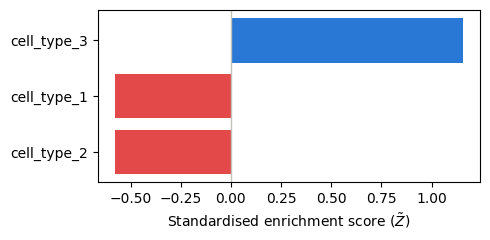

In [5]:
import matplotlib.pyplot as plt

ranked = results["CREST-GV_norm"].sort_values(ascending=False)
colors = ["#2a78d6" if v >= 0 else "#e34948" for v in ranked.values]

fig, ax = plt.subplots(figsize=(5, 2.5))
ax.barh(ranked.index[::-1], ranked.values[::-1], color=colors[::-1])
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel(r"Standardised enrichment score ($\tilde{Z}$)")
fig.tight_layout()
plt.show()


## 4. Coverage: per-variant signal at each cell type's bigWig

`get_coverage()` reports the raw bigWig signal under each input variant, per cell
type — useful for inspecting individual loci rather than the aggregate enrichment
statistic.


In [6]:
coverage = cgv.get_coverage()
coverage


Checking and cleaning genetic file...
Processed genetic file. Retained 3 rows.
Total number of used variants in CREST-GV: 3
Getting coverage ...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 61.71it/s]


,CHR_ID,CHR_POS,CHR_POS+1,SNPS,cell_type_1,cell_type_2,cell_type_3
0,chr10,801748,801749,rs60692108,1.5,3.75,0.75
1,chr10,823912,823913,rs74876360,1.5,3.75,0.75
2,chr10,840700,840701,chr10-840700-A-C,1.5,3.75,0.75


## 5. Running against the reference atlas instead

Pass `collection_name` (one of the keys printed in Section 0) instead of
`in_house_collection_path` to run against one of the 11 precomputed reference
collections. This requires access to the reference data collection itself (not
bundled with the package — see the main README's Installation section), so it isn't
run here, but the call is otherwise identical:

```python
cgv = crestgv(
    genetic="path/to/your_trait_variants.tsv",
    output="your_output_directory",
    collection_name="cad",
)
results = cgv.calculate_enrichment_score()
```

Or equivalently from the command line:

```bash
crestgv -g path/to/your_trait_variants.tsv -o your_output_directory -cn cad
```

Pass `-ra`/`--run_all` to run against every reference collection in one call, or
`-wc`/`--with_coverage` to also compute per-variant coverage.
